In [1]:
from datetime import datetime
import re
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import trim_mean

In [2]:
fname = "/scratch/gpfs/CSES/jdh4/sacct_data/della_queue_times_for_2026_expansion/della.data.uniq"
df = pd.read_csv(fname, sep="|", dtype=str, low_memory=False)

In [3]:
for col in ["start", "end", "eligible", "cputimeraw"]:
    df = df[pd.notna(df[col])]
    df = df[df[col].str.isnumeric()]
    df[col] = df[col].astype("int64")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 36824501 entries, 0 to 38501774
Data columns (total 12 columns):
 #   Column        Dtype 
---  ------        ----- 
 0   jobid         object
 1   users         object
 2   partition     object
 3   account       object
 4   start         int64 
 5   end           int64 
 6   eligible      int64 
 7   cputimeraw    int64 
 8   alloctres     object
 9   qos           object
 10  state         object
 11  timelimitraw  object
dtypes: int64(4), object(8)
memory usage: 3.6+ GB


In [5]:
df["elapsedraw"] = df.end - df.start
df = df[df.elapsedraw > 0]
df["job-length-hours"] = df["elapsedraw"] / 3600
df["cores"] = df["cputimeraw"] / df["elapsedraw"]

In [6]:
df["q-seconds"] = df.start - df.eligible
df["q-hours"] = df["q-seconds"] / 3600
df["year"] = df.start.apply(lambda ts: datetime.fromtimestamp(ts).year)
df["year"] = df["year"].astype("int64")
df = df[df.year >= 2023]

In [7]:
def gpus_per_job(tres: str) -> int:
    """Return the number of allocated GPUs."""
    gpus = re.findall(r"gres/gpu=\d+", tres)
    return int(gpus[0].replace("gres/gpu=", "")) if gpus else 0

In [8]:
df["gpus"] = df.alloctres.apply(gpus_per_job)
df["gpu-seconds"] = df.apply(lambda row:
                                 row["gpus"] * row["elapsedraw"]
                                 if row["partition"] != "mig"
                                 else row["gpus"] * row["elapsedraw"] / 7,
                                 axis="columns")
df["gpu-hours"] = df["gpu-seconds"] / 3600
df["cpu-hours"] = df["cputimeraw"] / 3600

In [9]:
df["q-hrs/cpu-hrs"] = df["q-hours"] / df["cpu-hours"]
df["q-hrs/gpu-hrs"] = df["q-hours"] / df["gpu-hours"]

In [10]:
df.describe().round(1)

/usr/licensed/anaconda3/2025.12/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:4671: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,start,end,eligible,cputimeraw,elapsedraw,job-length-hours,cores,q-seconds,q-hours,year,gpus,gpu-seconds,gpu-hours,cpu-hours,q-hrs/cpu-hrs,q-hrs/gpu-hrs
count,3.633700e+07,3.633700e+07,3.633700e+07,36337003.0,36337003.0,36337003.0,36337003.0,36337003.0,36337003.0,36337003.0,36337003.0,36337003.0,36337003.0,36337003.0,36337003.0,35968681.0
mean,1.741427e+09,1.741435e+09,1.741412e+09,39667.0,7757.2,2.2,4.5,14980.5,4.2,2024.7,0.2,1927.0,0.5,11.0,229.0,inf
std,3.668020e+07,3.667947e+07,3.668212e+07,393706.0,23153.9,6.4,11.6,62383.0,17.3,1.1,0.9,30653.2,8.5,109.4,5415.7,NaN
min,1.672549e+09,1.672549e+09,1.671459e+09,1.0,1.0,0.0,1.0,0.0,0.0,2023.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,1.708660e+09,1.708671e+09,1.708639e+09,216.0,98.0,0.0,1.0,111.0,0.0,2024.0,0.0,0.0,0.0,0.1,0.1,NaN
50%,1.746772e+09,1.746780e+09,1.746758e+09,2072.0,969.0,0.3,1.0,1443.0,0.4,2025.0,0.0,0.0,0.0,0.6,1.0,NaN
75%,1.775709e+09,1.775716e+09,1.775683e+09,11102.0,5494.0,1.5,4.0,10403.0,2.9,2026.0,0.0,0.0,0.0,3.1,6.7,NaN
max,1.793317e+09,1.793318e+09,1.793317e+09,190637568.0,2993753.0,831.6,1400.0,6226098.0,1729.5,2026.0,128.0,15886464.0,4412.9,52954.9,1673695.0,inf


In [11]:
df[df.gpus > 0].partition.value_counts()

partition
gpu              2670796
gputest           927707
pli-c             748082
gpu-shared        532908
mig               471791
cryoem            337067
ailab             228940
pli               147198
pli-lc             19246
gpu-ee             16425
cli                10008
grace               5543
gpu-wentzlaff       4586
rtx6000             3236
pli-p               3217
hackathon            928
motion               704
ailab-p               54
all                   24
Name: count, dtype: int64

In [12]:
df[df.gpus == 0].partition.value_counts()

partition
cpu              27965680
physics            847554
orfeus             576671
donia              373534
cryoem             229769
datascience        156236
pli-c               28027
gpu                 11737
malik                6394
pli                  4090
gpu-ee               2644
callan               1219
gputest               973
cli                   855
grace                 538
all                   514
gpu-shared            505
rtx6000               492
pli-lc                431
ailab                 279
gpu-wentzlaff         236
pli-p                  99
hackathon              44
mig                    19
motion                  3
Name: count, dtype: int64

In [13]:
df[(df.partition == "gpu") & (df.gpus == 0) & (df.year == 2025)]["cpu-hours"].sum()

np.float64(2246.148888888889)

In [14]:
df[(df.partition == "gpu") & (df.gpus >= 0)]["cpu-hours"].sum()

np.float64(44862909.1575)

In [15]:
df[(df.partition == "gpu") & (df.gpus == 0) & (df.year == 2026)][["users", "account", "year", "jobid"]]

,users,account,year,jobid
1274853,yk0581,ozidar,2026,11185052
1275182,yk0581,ozidar,2026,11185475
4149731,ck2867,jordanat,2026,13834105


# CPU-hours for 2026

In [16]:
df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"].min()

0.0002777777777777778

In [17]:
df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"].max()

24666.453333333335

In [18]:
df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"].sort_values().tail(20).round()

10083142    12333.0
10083137    12333.0
9119151     12333.0
11140980    12333.0
20756073    12333.0
11141534    12333.0
9941521     12334.0
10083090    12334.0
10083135    12334.0
10083088    12334.0
10083085    12334.0
19388933    12334.0
24735269    12334.0
9458829     12334.0
23639003    12335.0
24345400    12335.0
25392415    15415.0
21739491    18502.0
9323813     20587.0
9316678     24666.0
Name: cpu-hours, dtype: float64

In [19]:
df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"].div(24, axis=0).astype(int).value_counts()

cpu-hours
0      8628563
1       258297
2        84618
3        49740
4        32411
        ...   
175          1
206          1
157          1
166          1
334          1
Name: count, Length: 227, dtype: int64

Text(0, 0.5, 'Count')

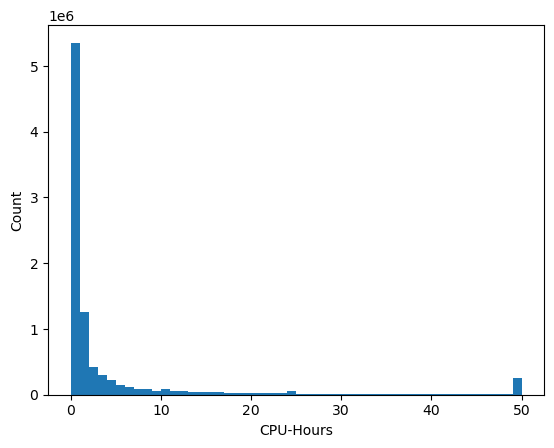

In [20]:
_ = plt.hist(df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"].clip(lower=0, upper=50), bins=50)
plt.xlabel("CPU-Hours")
plt.ylabel("Count")

In [21]:
trim_mean(df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"], proportiontocut=0.0)

np.float64(7.911565581693496)

In [22]:
trim_mean(df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"], proportiontocut=0.1)

np.float64(1.552820976834735)

In [23]:
trim_mean(df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"], proportiontocut=0.2)

np.float64(0.8695412959276513)

In [24]:
trim_mean(df[(df.partition == "cpu") & (df.qos == "short") & (df.year == 2026)]["cpu-hours"], proportiontocut=0.3)

np.float64(0.6397855144496256)

In [25]:
d = {"job-length-hours": ["size", lambda x: trim_mean(x, 0.2), "median"], "q-hours": [lambda x: trim_mean(x, 0.1), "median"], "gpu-hours": "sum"}
df[(df.year >= 2025) & (df.gpus > 0)].groupby(["partition"]).agg(d).round(1)

job-length-hours                      q-hours         gpu-hours
                          size <lambda_0> median <lambda_0> median        sum
partition                                                                    
ailab                   228940        0.5    0.3        1.4    0.3  1057563.3
ailab-p                     54        0.3    0.2        0.0    0.0       24.0
cryoem                  251771        0.3    0.2        0.3    0.0   751028.1
gpu                    1398087        0.7    0.4        4.4    1.8  4576632.4
gpu-ee                    6842        0.4    0.2        0.5    0.0    17002.9
gpu-shared              115323        1.5    1.2        7.1    3.4   449107.6
gpu-wentzlaff             4253        0.4    0.3        0.6    0.0    13260.9
gputest                 690351        0.1    0.1        0.1    0.0   402687.4
grace                     5439        0.2    0.1        0.1    0.0     7285.5
hackathon                  928        0.0    0.0        0.0    0.0       61.0
mig                     311394        0.1    0.1        1.1    0.3    75491.4
pli                     110161        0.9    0.4        2.9    0.7   672077.5
pli-c                   622984        0.3    0.2        1.0    0.1  3597123.0
pli-lc                   18922        1.3    0.6        2.2    0.2   130080.3
pli-p                     3217        1.3    1.3        0.5    0.1   139530.8
rtx6000                   3236        0.9    0.4        1.7    0.0    12653.8

In [26]:
d = {"job-length-hours": ["size", lambda x: trim_mean(x, 0.1), "median"], "q-hours": [lambda x: trim_mean(x, 0.1), "median"], "gpu-hours": "sum"}
df[(df.year >= 2025) & (df.gpus > 0)].groupby(["partition"]).agg(d).round(1)

job-length-hours                      q-hours         gpu-hours
                          size <lambda_0> median <lambda_0> median        sum
partition                                                                    
ailab                   228940        0.7    0.3        1.4    0.3  1057563.3
ailab-p                     54        0.3    0.2        0.0    0.0       24.0
cryoem                  251771        0.4    0.2        0.3    0.0   751028.1
gpu                    1398087        1.1    0.4        4.4    1.8  4576632.4
gpu-ee                    6842        0.7    0.2        0.5    0.0    17002.9
gpu-shared              115323        2.1    1.2        7.1    3.4   449107.6
gpu-wentzlaff             4253        0.5    0.3        0.6    0.0    13260.9
gputest                 690351        0.2    0.1        0.1    0.0   402687.4
grace                     5439        0.3    0.1        0.1    0.0     7285.5
hackathon                  928        0.0    0.0        0.0    0.0       61.0
mig                     311394        0.3    0.1        1.1    0.3    75491.4
pli                     110161        1.4    0.4        2.9    0.7   672077.5
pli-c                   622984        0.7    0.2        1.0    0.1  3597123.0
pli-lc                   18922        2.0    0.6        2.2    0.2   130080.3
pli-p                     3217        1.7    1.3        0.5    0.1   139530.8
rtx6000                   3236        1.2    0.4        1.7    0.0    12653.8

In [27]:
d = {"job-length-hours": ["size", "mean", "median"], "q-hours": ["mean", "median"], "gpu-hours": "sum"}
df[(df.partition == "gpu") | (df.partition == "gputest") | (df.partition == "gpu-shared") | (df.partition == "mig")].groupby(["year", "partition"]).agg(d).round(1)

job-length-hours             q-hours         gpu-hours
                            size mean median    mean median        sum
year partition                                                        
2023 gpu                  898224  2.2    0.2     6.7    2.1  2519972.8
     gputest              118798  0.3    0.1     0.4    0.0   138051.6
     mig                   90002  2.0    0.1     3.3    0.7    26320.6
2024 gpu                  386169  4.0    0.6    10.2    3.2  1842403.7
     gpu-shared           417947  1.9    0.4     9.5    2.0   957168.8
     gputest              119529  0.3    0.1     0.3    0.0    79271.5
     mig                   70414  3.9    0.6     4.4    0.0    39599.8
2025 gpu                  652114  3.0    0.3     8.2    1.7  2203529.6
     gpu-shared           115466  3.6    1.2    14.3    3.3   449107.6
     gputest              271547  0.2    0.0     0.3    0.0   117943.5
     mig                   96032  2.9    0.1     4.6    0.9    40720.9
2026 gpu                  746026  2.9    0.4    12.2    1.8  2373102.8
     gputest              418806  0.3    0.1     0.5    0.0   284743.9
     mig                  215362  1.1    0.0     3.7    0.2    34770.6

In [28]:
d = {"job-length-hours": ["size", "mean", "median"], "q-hours": ["mean", "median"], "gpu-hours": "sum"}
df[(df.partition == "gpu")].groupby(["year", "qos"]).agg(d).round(1)

job-length-hours              q-hours         gpu-hours
                                size  mean median    mean median        sum
year qos                                                                   
2023 enabled                    1842   8.7    4.3     8.3    8.5    21783.4
     gpu-long                   3639  42.9   17.7    38.1    1.6   261008.6
     gpu-medium                33638  16.7    5.1     7.5    0.6   763062.3
     gpu-short                859105   1.5    0.2     6.6    2.2  1474118.5
2024 della-shakemov              570   0.2    0.1     7.0    1.0      514.1
     enabled                      25  91.4  119.3    52.4   38.0     7910.0
     gpu-long                   4288  42.6   14.0    16.3    0.9   321175.0
     gpu-medium                27139  23.5   15.0    14.7    1.4   743899.9
     gpu-short                354147   2.0    0.6     9.7    3.3   768904.7
2025 della-shakemov                4   0.2    0.2     1.7    0.2        3.7
     enabled                     306   1.2    0.3     1.7    1.2      592.7
     gpu-long                   3950  43.9   17.1    27.1    0.8   231528.2
     gpu-medium                37767  16.3    0.5    12.3    0.1   686597.9
     gpu-short                609873   2.0    0.3     7.8    1.8  1284748.5
     gpu-test                    214   0.3    0.0     4.9    1.1       58.7
2026 della-shakemov                7   0.2    0.0     1.3    0.7        4.8
     gpu-long                   2510  50.2   29.4    49.9    2.7   149757.4
     gpu-medium                20525  21.5   12.3    37.2    4.0   485268.4
     gpu-short                722932   2.2    0.4    11.3    1.8  1738038.4
     gpu-test                     29   0.2    0.1     1.5    0.2        5.0
     pli-short                    20   1.4    0.6     0.2    0.0       28.7
     short                         2   0.0    0.0     0.1    0.1        0.0
     test                          1   0.0    0.0     0.0    0.0        0.0

In [29]:
d = {"job-length-hours": ["size", "mean", "median"], "q-hours": ["mean", "median"], "gpu-hours": "sum"}
df[(df.partition == "pli") | (df.partition == "pli-c") | (df.partition == "pli-lc") | (df.partition == "pli-p") | (df.partition == "ailab") | (df.partition == "ailab-p")].groupby(["year", "partition"]).agg(d).round(1)

job-length-hours             q-hours         gpu-hours
                           size mean median    mean median        sum
year partition                                                       
2023 pli                    421  5.2    0.9     1.8    0.0    10740.4
2024 pli                  37013  3.3    0.4     2.1    0.0   310678.8
     pli-c               136182  2.2    0.4     1.6    0.0  1173762.6
     pli-lc                 325  3.6    0.1     1.6    0.0     2200.6
2025 ailab                 7424  4.6    0.5     1.3    0.0    93734.6
     pli                  74754  3.7    0.3     7.9    0.3   452962.6
     pli-c               323915  2.0    0.1     2.0    0.0  1654194.1
     pli-lc               13999  4.0    1.1     5.3    0.1    95744.0
     pli-p                 3297  3.1    1.3     1.2    0.1   128068.9
2026 ailab               221795  2.1    0.3     4.7    0.4   963828.7
     ailab-p                 54  0.4    0.2     0.1    0.0       24.0
     pli                  39100  3.6    0.6    10.3    1.1   219114.9
     pli-c               316012  1.9    0.2     4.3    0.3  1942928.9
     pli-lc                5353  2.7    0.4     7.9    0.4    34336.3
     pli-p                   19  8.9   12.1    18.2   13.8    11461.9

In [30]:
df[(df.partition == "cpu") & (df.qos == "short") & (df["q-hours"] == 0)]

,jobid,users,partition,account,start,end,eligible,cputimeraw,alloctres,qos,...,cores,q-seconds,q-hours,year,gpus,gpu-seconds,gpu-hours,cpu-hours,q-hrs/cpu-hrs,q-hrs/gpu-hrs
2719,10002461,dj3371,cpu,amoeller,1781949554,1781949971,1781949554,3336,"billing=8,cpu=8,mem=1200M,node=1",short,...,8.0,0,0.0,2026,0,0.0,0.0,0.926667,0.0,NaN
4312,10004498,bl3615,cpu,chij,1781954669,1781954711,1781954669,168,"billing=32,cpu=4,mem=128G,node=1",short,...,4.0,0,0.0,2026,0,0.0,0.0,0.046667,0.0,NaN
4450,10004678_0,mt0207,cpu,shs,1781955170,1781962484,1781955170,175536,"billing=24,cpu=24,mem=5G,node=1",short,...,24.0,0,0.0,2026,0,0.0,0.0,48.760000,0.0,NaN
4451,10004678_10,mt0207,cpu,shs,1781955170,1781960985,1781955170,139560,"billing=24,cpu=24,mem=5G,node=1",short,...,24.0,0,0.0,2026,0,0.0,0.0,38.766667,0.0,NaN
4452,10004678_11,mt0207,cpu,shs,1781955170,1781960472,1781955170,127248,"billing=24,cpu=24,mem=5G,node=1",short,...,24.0,0,0.0,2026,0,0.0,0.0,35.346667,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38493339,9994943,yf9876,cpu,subotnik,1781926620,1781928868,1781926620,2248,"billing=1,cpu=1,mem=1000M,node=1",short,...,1.0,0,0.0,2026,0,0.0,0.0,0.624444,0.0,NaN
38493340,9994944,yf9876,cpu,subotnik,1781926620,1781928862,1781926620,2242,"billing=1,cpu=1,mem=1000M,node=1",short,...,1.0,0,0.0,2026,0,0.0,0.0,0.622778,0.0,NaN
38494399,9996195,yf9876,cpu,subotnik,1781930970,1781933356,1781930970,2386,"billing=1,cpu=1,mem=1000M,node=1",short,...,1.0,0,0.0,2026,0,0.0,0.0,0.662778,0.0,NaN
38495300,9997031_10,zx0010,cpu,shinseir,1781943609,1781954591,1781943609,175712,"billing=16,cpu=16,mem=64G,node=1",short,...,16.0,0,0.0,2026,0,0.0,0.0,48.808889,0.0,NaN


In [31]:
d = {"job-length-hours": ["size", "mean", lambda x: trim_mean(x, 0.1), "median"], "q-hours": ["mean", lambda x: trim_mean(x, 0.1), "median", "sum"], "q-hrs/cpu-hrs": ["mean", lambda x: trim_mean(x, 0.1), "median"], "q-hrs/gpu-hrs": ["mean", lambda x: trim_mean(x, 0.1), "median"], "cpu-hours": "sum", "gpu-hours": "sum", "users": "nunique"}
details = df.groupby(["year", "qos", "partition"]).agg(d).round(1)
details.to_csv("della_wait_times_and_job_length_by_year_partition_qos.csv")

In [32]:
print(details.to_string())

                                  job-length-hours                          q-hours                               q-hrs/cpu-hrs                    q-hrs/gpu-hrs                     cpu-hours  gpu-hours   users
                                              size   mean <lambda_0> median    mean <lambda_0> median         sum          mean <lambda_0>  median          mean <lambda_0> median         sum        sum nunique
year qos            partition                                                                                                                                                                                    
2023 ccallan        callan                     831    7.6        6.1    3.2     0.9        0.0    0.0       722.3           3.1        0.2     0.0           inf        inf    inf     27587.9        0.0       1
     della-cryoem   cryoem                   90337    3.2        0.3    0.0     1.4        0.2    0.0    129568.0          85.7        2.0     0.4           inf

In [33]:
df[(df.year == 2025) & ((df.partition == "gpu") | (df.partition == "gputest") | (df.partition == "gpu-shared"))]["gpu-hours"].sum()

np.float64(2770580.723888889)

In [34]:
df[(df.year == 2025) & ((df.partition == "gpu") | (df.partition == "gputest") | (df.partition == "gpu-shared"))]["q-hours"].sum()

np.float64(7091135.319166667)

In [35]:
df[(df.year == 2025) & ((df.partition == "gpu") | (df.partition == "gputest") | (df.partition == "gpu-shared"))]["users"].unique().size

880

# CPU

In [36]:
df[(df.year == 2025) & ((df.partition == "cpu") | (df.partition == "all"))]["users"].unique().size

1431

In [37]:
df[(df.year == 2025) & ((df.partition == "cpu") | (df.partition == "all"))]["cpu-hours"].sum()

np.float64(90074585.88833332)

In [38]:
df[(df.year == 2025) & ((df.partition == "cpu") | (df.partition == "all"))]["q-hours"].sum()

np.float64(23129778.505555555)

In [39]:
d = {"job-length-hours": ["size", "mean", "median"], "q-hours": ["mean", "median"], "cpu-hours": "sum", "gpu-hours": "sum"}
df[(df.year >= 2025) & (df.gpus == 0)].groupby(["partition"]).agg(d).round(1)

job-length-hours             q-hours           cpu-hours  \
                          size mean median    mean median          sum   
partition                                                                
ailab                      279  0.9    0.2     0.2    0.0       6532.8   
all                        306  1.3    0.4     0.1    0.0       9474.1   
cpu                   16540403  2.0    0.2     3.1    0.3  184592801.8   
cryoem                   97665  0.5    0.1     2.0    0.0     486249.0   
datascience              15579  5.4    0.5     3.4    0.0    1559627.2   
donia                   288278  0.8    0.0     7.9    1.8    1430732.7   
gpu                         53  0.3    0.3     0.2    0.0       2246.3   
gpu-ee                    1777  1.3    0.1     1.1    0.0      38446.4   
gpu-shared                 143  0.4    0.5     0.5    0.0       9135.4   
gpu-wentzlaff              235  1.1    0.3     0.5    0.0       4638.4   
gputest                      2  0.6    0.6     0.0    0.0          2.2   
grace                      528  0.5    0.1     0.5    0.0       8060.4   
hackathon                   44  0.1    0.0     0.0    0.0          4.2   
malik                     2517  0.5    0.0     0.2    0.0      27579.8   
physics                  66918  1.2    0.1     0.4    0.0     431217.2   
pli                       3693  1.1    0.1     0.3    0.0      52798.4   
pli-c                    16943  1.4    0.0     0.2    0.0     624696.9   
pli-lc                     430  1.3    0.6     0.0    0.0      64043.9   
pli-p                       99  1.2    0.1     0.0    0.0       1427.4   
rtx6000                    492  0.1    0.0     0.1    0.0        631.7   

              gpu-hours  
                    sum  
partition                
ailab               0.0  
all                 0.0  
cpu                 0.0  
cryoem              0.0  
datascience         0.0  
donia               0.0  
gpu                 0.0  
gpu-ee              0.0  
gpu-shared          0.0  
gpu-wentzlaff       0.0  
gputest             0.0  
grace               0.0  
hackathon           0.0  
malik               0.0  
physics             0.0  
pli                 0.0  
pli-c               0.0  
pli-lc              0.0  
pli-p               0.0  
rtx6000             0.0